# NAME: Harisankar.S
# REG NO: 212224240051

Face shape: (1109, 941, 3)


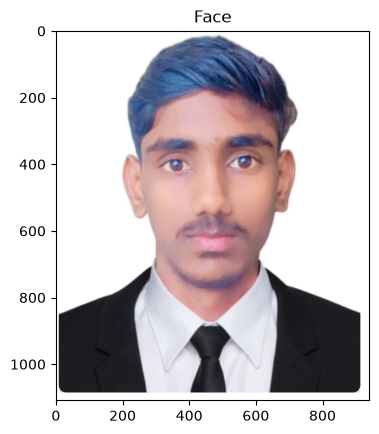

In [56]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

#Load face image
faceImage = cv2.imread("hari.jpg")
plt.imshow(faceImage[:,:,::-1]); plt.title("Face")
print("Face shape:", faceImage.shape)

Glass shape: (350, 350, 3)


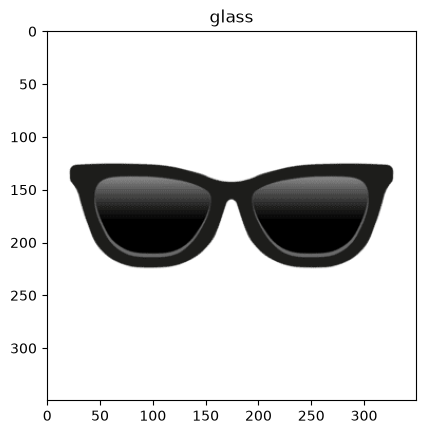

In [57]:
glass= cv2.imread("glass.png")
plt.imshow(glass[:,:,::-1]); plt.title("glass")
print("Glass shape:", glass.shape)

Text(0.5, 1.0, 'Sunglass Color channels')

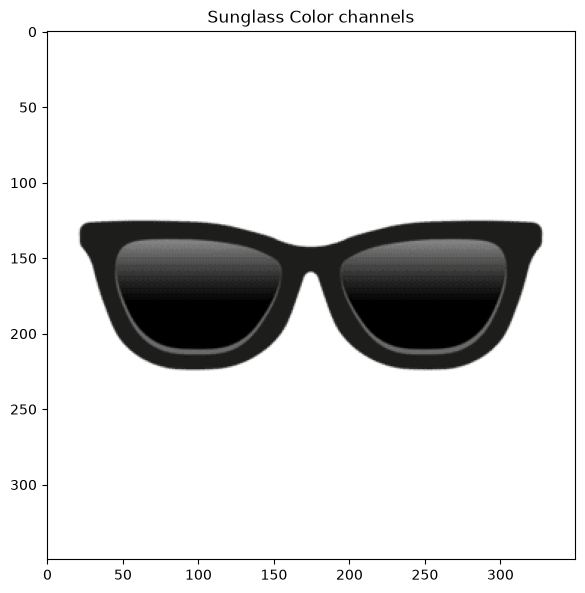

In [58]:
glassBGR = glass[:,:,0:3]
glassGray = cv2.cvtColor(glassBGR, cv2.COLOR_BGR2GRAY)
_, glassMask1 = cv2.threshold(glassGray, 240, 255, cv2.THRESH_BINARY_INV)  # detect non-white

plt.figure(figsize=[15,15])
#Show sunglasses color channels
plt.subplot(121)
plt.imshow(glassBGR[:,:,::-1])  # BGR → RGB
plt.title('Sunglass Color channels')

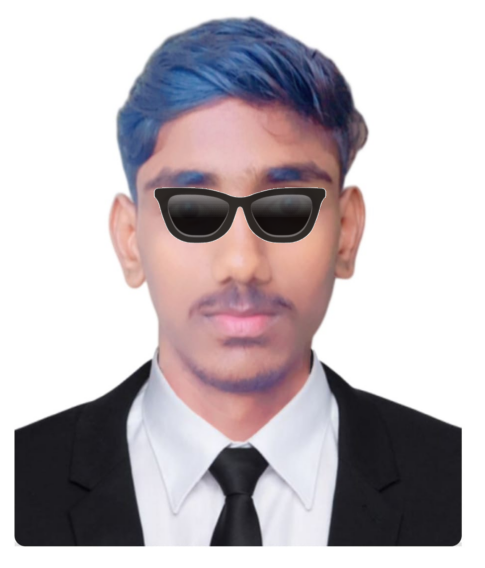

In [59]:

# Split channels
glass_rgb = glass_resized[:, :, :3]
glass_gray = cv2.cvtColor(glass_resized, cv2.COLOR_BGR2GRAY)

_, mask = cv2.threshold(
    glass_gray, 250, 280, cv2.THRESH_BINARY_INV
)

alpha = (mask.astype(np.float32) / 255.0) * 0.9

# Position and crop the overlay safely
y = y - 9
x = max(0, x)
y = max(0, y)

h = min(new_h, face_h - y)
w = min(new_w, face_w - x)

glass_rgb = glass_rgb[:h, :w].astype(np.float32)
alpha = alpha[:h, :w]
roi = faceImage[y:y+h, x:x+w].astype(np.float32)

# Blend glasses with the face
for c in range(3):
    roi[:, :, c] = (
        alpha * glass_rgb[:, :, c]
        + (1 - alpha) * roi[:, :, c]
    )

faceImage[y:y+h, x:x+w] = np.clip(
    roi, 0, 255
).astype(np.uint8)

# Display output
plt.figure(figsize=(6, 8))
plt.imshow(cv2.cvtColor(faceImage, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()
